In [1]:
from matplotlib import pyplot as plt
import numpy as np

In [2]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/home/sam-reiter/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### LCD

Experiment: The polarization of the LCD (EIZO S1504; https://www.eizo.co.jp/products/lcd/s1504/) was measured using a light detector and a linear polarizor.

* White LED light was used as the back light.
* Pixel value of the LCD was changed from 0 to 250 at  step of 10 using Psychopy
* A light detector with a linear polarizor was used to measure the light intensity.
* The polarizer angle was 240 (parallel with the back polarizer) or 330 (parpendicular with the back polarizer)

In [3]:
x = np.arange(0, 251, 10)

In [4]:
# angle = 220
y1 = np.array([147.4,147,146.1,144.9,143.5,141.8,140,137.9,135.6,133,130.2,127.3,124.2,120.4,116.3,112.2,108,103.5,98.6,93.5,88.1,82.5,76.7,70.5,63.9,58])
# angle = 265
y2 = np.array([74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.8,74.9,74.9,74.9,74.9,74.9,75,75,75.1,75.1,75.2,75.2,75.3,75.3])
# angle = 310
y3 = np.array([3.37, 3.78, 4.74, 5.95, 7.38, 9.06, 10.96, 13.03, 15.32, 18, 20.7, 23.7, 27.1, 30.6, 34.8, 39, 43.3, 47.8, 52.7, 57.9, 63.3, 69, 75, 81.3, 88.1, 94])
# angle = 175 or 355
y4 = np.array([77.4,77.3,77.3,77.3,77.2,77.2,77.1,77.1,77,76.9,76.9,76.8,76.7,76.6,76.5,76.4,76.3,76.1,76,75.9,75.7,75.6,75.4,75.2,75.1,74.9])

### Degree of linear polarization

In [8]:
s0 = (y1 + y2 + y3 + y4) / 2
s1 = y1 - y3
s2 = y2 - y4

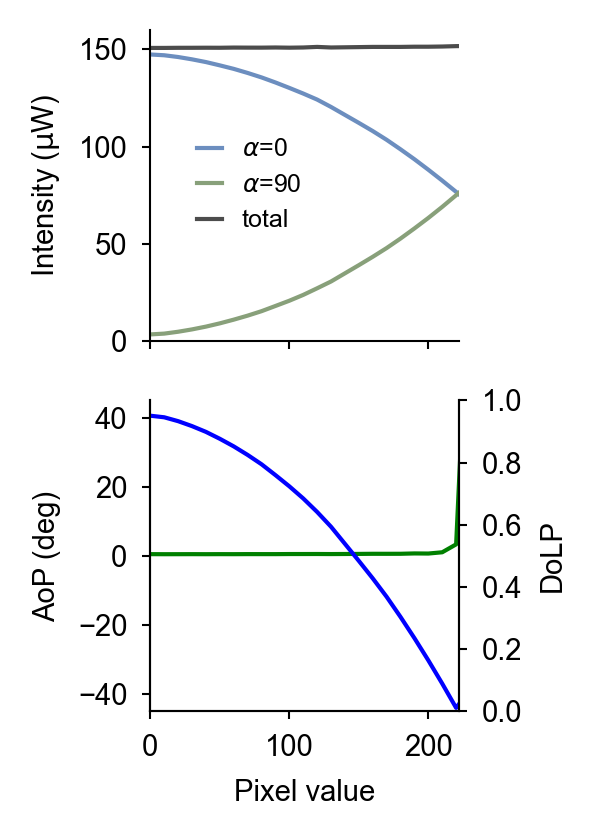

In [23]:
dolp = np.sqrt(s1 ** 2 + s2 **2) / s0
aop = np.rad2deg(0.5 * np.arctan2(s2, s1))
aop = np.abs(aop % 180)
aop = np.where(aop > 90, 180 - aop, aop)

fig, axs = plt.subplots(2, 1, figsize=(2, 2.8), dpi=300, sharex=True)

ax = axs[0]
ax.plot(x, y1, label=r"$\alpha$=0", lw=1, color="#6C8EBF")
ax.plot(x, y3, label=r"$\alpha$=90", lw=1, color="#88A07A")
ax.plot(x, y1 + y3, label="total", lw=1, color="#4C4C4C")
ax.set_ylabel(r"Intensity ($\mathrm{\mu}$W)")
ax.set_ylim([0, 160])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", labelbottom=False)
ax.legend(loc="center", bbox_to_anchor=(0.32, 0.5), handlelength=1, fontsize=6, frameon=False)

ax = axs[1]
ax.plot(x, aop, color="green", lw=1)
ax.set_xlabel("Pixel value")
ax.set_ylabel("AoP (deg)")
ax.set_ylim([-45, 45])
ax.set_xlim([0,222])
ax.set_xticks([0, 100, 200])
ax.spines['top'].set_visible(False)

ax2 = ax.twinx()
ax2.plot(x, dolp, color="blue", lw=1)
ax2.set_ylabel("DoLP")
ax2.set_ylim([0, 1])
ax2.spines['top'].set_visible(False)

plt.tight_layout()
plt.savefig("/home/sam-reiter/LCD_calibration_2_aop_dolp.pdf", bbox_inches="tight", transparent=True)
plt.show()